<a href="https://colab.research.google.com/github/tanmay23-blip/tanmay_ees_322_lab1/blob/main/ees322lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install -U geemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 40.3 MB/s eta 0:00:00


In [2]:
import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
collection_composite = raw_collection.median()

# Create a geemap.Map object.
# Centering the map on the sample_point defined earlier
Map = geemap.Map(center=[CENTER_LAT, CENTER_LON], zoom=9)

# Define visualization parameters for Landsat 8 surface reflectance.
viz_params = {
    'bands': ['SR_B4', 'SR_B3', 'SR_B2'],  # Red, Green, Blue
    'min': 0,
    'max': 3000,
    'gamma': 1.4,
}

# Add the composite image to the map.
Map.addLayer(collection_composite, viz_params, 'Median Composite')

# Add the Area of Interest (AOI) to the map.
Map.addLayer(aoi, {'color': 'red'}, 'AOI')

# Display the map.
Map

In [4]:
PROJECT_ID = 'tanmayproject1-505109'

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

print('Earth Engine initialised.')

Earth Engine initialised.


In [42]:
CENTER_LON = 76.63925
CENTER_LAT = 12.29791

centre = ee.Geometry.Point([CENTER_LON, CENTER_LAT])
aoi = centre.buffer(20_000).bounds()
sample_point = centre

In [43]:
START_DATE = '2024-01-01'
END_DATE = '2025-12-31'
MAX_CLOUD = 60

raw_collection = (
    ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
    .filterBounds(aoi)
    .filterDate(START_DATE, END_DATE)
    .filter(ee.Filter.lt('CLOUD_COVER', MAX_CLOUD))
)

scene_count = raw_collection.size().getInfo()
print('Number of matching scenes:',scene_count)

if scene_count == 0:
  raise ValueError('No scenes found. Increase the date range or MAX_CLOUD')

Number of matching scenes: 82


In [44]:
def preprocess_landsat8(image):
    qa = image.select('QA_PIXEL')

    clear_mask = (
        qa.bitwiseAnd(1 << 1).eq(0)
        .And(qa.bitwiseAnd(1 << 2).eq(0))
        .And(qa.bitwiseAnd(1 << 3).eq(0))
        .And(qa.bitwiseAnd(1 << 4).eq(0))
        .And(qa.bitwiseAnd(1 << 5).eq(0))
    )

    saturation_mask = image.select('QA_RADSAT').eq(0)
    optical = image.select('SR_B[1-7]').multiply(0.0000275).add(-0.2)

    return (
        image.addBands(optical, None, True)
        .updateMask(clear_mask)
        .updateMask(saturation_mask)
    )

raw_image = ee.Image(raw_collection.sort('CLOUD_COVER').first())
image = preprocess_landsat8(raw_image)

print('Product ID:', raw_image.get('LANDSAT_PRODUCT_ID').getInfo())
print('Aquisition date:',raw_image.date().format('YYYY-MM-dd').getInfo())
print('scene cloud cover (%): ', raw_image.get('CLOUD_COVER').getInfo())


Product ID: LC08_L2SP_144051_20240207_20240212_02_T1
Aquisition date: 2024-02-07
scene cloud cover (%):  0


In [45]:
Map = geemap.Map()
Map.centerObject(aoi, 10)

true_color = {
    'bands': ['SR_B4', 'SR_B3', 'SR_B2'],
    'min': 0.0,
    'max': 0.30,
}

false_color = {
    'bands': ['SR_B5', 'SR_B4', 'SR_B3'],
    'min': 0.0,
    'max': 0.35,
}

Map.addLayer(image.clip(aoi), true_color, 'True colour (4-3-2)')
Map.addLayer(image.clip(aoi), false_color, 'False colour (5-4-3)', False)
Map.addLayer(aoi, {'color': 'yellow'}, 'AOI', False)
Map.addLayer(sample_point, {'color': 'red'}, 'Sample point')
Map



Map(center=[12.297923766704894, 76.63955421133551], controls=(WidgetControl(options=['position', 'transparent_…

In [46]:

band_names = [
    ('SR_B1', 'Coastal aerosol'),
    ('SR_B2', 'Blue'),
    ('SR_B3', 'Green'),
    ('SR_B4', 'Red'),
    ('SR_B5', 'NIR'),
    ('SR_B6', 'SWIR1'),
    ('SR_B7', 'SWIR2'),
]

BandMap = geemap.Map()
BandMap.centerObject(aoi, 10)

for band, label in band_names:
    BandMap.addLayer(
        image.select(band).clip(aoi),
        {'min': 0.0, 'max': 0.35},
        label,
        False,
    )

BandMap.addLayer(image.select('SR_B4').clip(aoi),
                 {'min': 0.0, 'max': 0.35}, 'Red - active')
BandMap.addLayer(sample_point, {'color': 'red'}, 'Sample point')
BandMap





Map(center=[12.297923766704903, 76.63955421133551], controls=(WidgetControl(options=['position', 'transparent_…

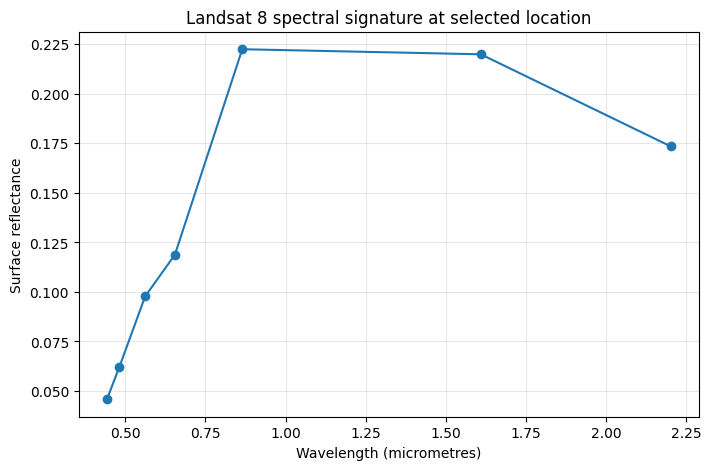

In [49]:

bands = ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7']
wavelength_um = [0.443, 0.482, 0.562, 0.655, 0.865, 1.609, 2.201]

sample_area = sample_point.buffer(45)

spectrum = (
    image.select(bands)
    .reduceRegion(
        reducer=ee.Reducer.mean(),
         geometry= sample_area,
                 scale=30,
        maxPixels=1_000_000,
    )
    .getInfo()
)

reflectance = [spectrum.get(b, np.nan) for b in bands]

spectral_table = pd.DataFrame({
    'Band': bands,
    'Wavelength_um': wavelength_um,
    'Surface_reflectance': reflectance,
})

spectral_table

plt.figure(figsize=(8, 5))
plt.plot(wavelength_um, reflectance, marker='o')
plt.xlabel('Wavelength (micrometres)')
plt.ylabel('Surface reflectance')
plt.title('Landsat 8 spectral signature at selected location')
plt.grid(True, alpha=0.3)
plt.show()


